# One term, three ends

The order of reduction does not change where a net ends up. It does decide **whether** it gets there.

This notebook uses the combinators S, K and I as agents (the `ski` table). A term is written in prefix form: a backtick applies the next term to the one after it. `K x y` reduces to `x`; `I x` to `x`; `S x y z` to `x z (y z)`.

Take `Ω`, which is ```` ```SII``SII ```` and reduces to itself without end, and the term `K I Ω`. `K` discards its second argument, so the term has the normal form `I`.

In [1]:
%demo

One term, K I Ω, where Ω reduces to itself without end. K discards its second argument,
so the term has the normal form I. Whether a net reaches it depends on which pairs fire.

ski table, by need: only the pairs the answer depends on
  answer I; 2 interactions, of which 1 contractions; stopped because: wanted; active pairs left: 2
ski table, every pair fired: Ω runs although K will discard it
  answer none: stopped at the cap of 300 interactions; 301 interactions, of which 149 contractions; stopped because: interactions; active pairs left: 3
lazy table, every pair fired: the demand is carried in the net, and no work is shared
  answer I; 18 interactions, of which 1 contractions; stopped because: normal; active pairs left: 0

By need stops with active pairs left: what it reaches is a normal form of what the root can
reach, not of the whole net. Ω is still there, unreduced, until it is swept away.


## By need

Fire only the pairs the answer depends on. `K` takes `I`, then discards `Ω`, and `Ω` is never touched.

In [2]:
%ski ``KI```SII``SII

I
stopped: the value wanted is there (wanted); 2 interactions; 2 active pairs left; collect 1, contract 1


It stopped with active pairs left: `Ω` is still there, unreduced. What reduction by need reaches is a normal form of what the answer can reach, not of the whole net.

## Every pair fired

This is what a machine without a strategy does. `Ω` runs although `K` is about to discard it, and the eraser cannot catch it, because an eraser acts on a finished value and `Ω` never finishes.

In [3]:
%cap 300
%ski ``KI```SII``SII --rounds

a run stops after 300 interactions


no answer: the cap was reached
stopped: the cap was reached (interactions); 301 interactions, in 101 rounds, the widest of 3; 3 active pairs left; collect 5, contract 149, copy 147


## Every pair fired, with the demand carried in the net

The `lazy` table makes an application inert until a demand, itself an agent, reaches it. Now every pair can be fired and only wanted work is done.

In [4]:
%cap 10000
%ski ``KI```SII``SII --lazy

a run stops after 10000 interactions


I
stopped: no active pair is left (normal); 18 interactions, in 9 rounds, the widest of 4; 0 active pairs left; arrive 3, collect 1, contract 1, demand 2, erase 11


## What that costs

The `lazy` table does not share work. Take a term that uses its argument twice, `S I I x`, where `x` takes six steps to evaluate.

By need, `x` is evaluated once and the result copied: nine contractions in all.

In [5]:
%ski ```SII```SKK```SKK```SKK0

`00
stopped: the value wanted is there (wanted); 25 interactions; 3 active pairs left; collect 12, contract 9, copy 4


By the `lazy` table, each use evaluates its own copy: fifteen, the same as ordinary term rewriting.

In [6]:
%ski ```SII```SKK```SKK```SKK0 --lazy

`00
stopped: no active pair is left (normal); 193 interactions, in 77 rounds, the widest of 7; 0 active pairs left; arrive 20, collect 21, contract 15, copy 61, demand 22, erase 54


Why not both? Because an agent can be reached only through its one principal port, a piece of net that waits to be asked cannot be woken from two sides. So in a net of agents with every pair fired, stopping when you should and sharing work pull against each other. The argument, and measurements on larger programs, are in [vine-aviary](https://github.com/sigilante/vine-aviary).

## Looking inside

The `ski` table can be used directly too. `S K K 0` as a net, by need for the free port `out`:

12 agents, 27 rules, with signs; 0 problems


schedule: need, for the free port out


the net:


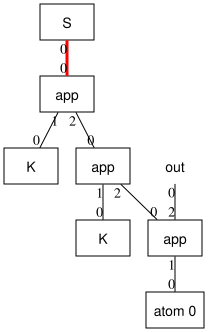

stopped: the value wanted is there (wanted); 6 interactions; 1 active pairs left; collect 3, contract 2, copy 1


what is left:


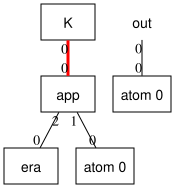

In [7]:
%system ski
%schedule need out
S = app (K a); a = app (K b); b = app (atom 0 out)